# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Daffa Taufiqulhafizh
- **Email:** daffataufiqulhafizh221@gmail.com
- **ID Dicoding:** dapp_221

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Kategori produk apa saja yang menyumbang total revenue tertinggi (top 10) dan terendah (bottom 5) selama periode Januari 2017 – Agustus 2018, dan berapa persen kontribusi 5 kategori teratas terhadap total revenue?
- **Pertanyaan 2:** Seberapa besar pengaruh keterlambatan pengiriman terhadap rata-rata review score pelanggan, dan di 10 state mana (dengan minimal 100 pesanan) persentase pesanan terlambat paling tinggi selama periode Januari 2017 – Agustus 2018?

## Import Semua Packages/Library yang Digunakan

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data

#### Load tabel customers, orders, order_items, order_reviews, products, dan translasi kategori

In [9]:
import os

DATA_DIR = "/content/" if os.path.exists("/content/orders_dataset.csv") else "data/"

In [10]:
DATA_DIR = "/content/"

customers_df = pd.read_csv(DATA_DIR + "customers_dataset.csv")
orders_df = pd.read_csv(DATA_DIR + "orders_dataset.csv")
order_items_df = pd.read_csv(DATA_DIR + "order_items_dataset.csv")
order_reviews_df = pd.read_csv(DATA_DIR + "order_reviews_dataset.csv")
products_df = pd.read_csv(DATA_DIR + "products_dataset.csv")
category_translation_df = pd.read_csv(DATA_DIR + "product_category_name_translation.csv")

orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight:**
- Ada 6 tabel yang dipakai: customers, orders, order_items, order_reviews, products, dan translasi kategori produk.
- Tabel orders (99.441 pesanan) menjadi penghubung utama: order_items dan order_reviews terhubung lewat `order_id`, customers lewat `customer_id`, dan products lewat `product_id` pada order_items.

### Assessing Data

#### Identifying missing value, tipe data tidak sesuai, duplikat parsial, dan data tidak konsisten

In [11]:
dfs = {
    "customers": customers_df,
    "orders": orders_df,
    "order_items": order_items_df,
    "order_reviews": order_reviews_df,
    "products": products_df,
    "category_translation": category_translation_df,
}

for name, df in dfs.items():
    print(f"=== {name} {df.shape} ===")
    print("Missing value:")
    print(df.isna().sum()[df.isna().sum() > 0])
    print("Duplikat:", df.duplicated().sum())
    print()

orders_df.info()

=== customers (99441, 5) ===
Missing value:
Series([], dtype: int64)
Duplikat: 0

=== orders (99441, 8) ===
Missing value:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64
Duplikat: 0

=== order_items (112650, 7) ===
Missing value:
Series([], dtype: int64)
Duplikat: 0

=== order_reviews (99224, 7) ===
Missing value:
review_comment_title      87656
review_comment_message    58247
dtype: int64
Duplikat: 0

=== products (32951, 9) ===
Missing value:
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64
Duplikat: 0

=== category_translation (71, 2) ===
Missing value:
Series([], dtype: int64)
Duplikat: 0

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data co

In [12]:
# Rentang tanggal & status pesanan
print("Rentang tanggal pembelian:", orders_df["order_purchase_timestamp"].min(), "-", orders_df["order_purchase_timestamp"].max())
print(orders_df["order_status"].value_counts())

# Status pesanan vs tanggal sampai yang kosong
print(pd.crosstab(orders_df["order_status"], orders_df["order_delivered_customer_date"].isna()))

# Kategori produk tanpa translasi
no_translation = set(products_df["product_category_name"].dropna()) - set(category_translation_df["product_category_name"])
print("Kategori tanpa translasi:", no_translation)

# Review: ada review_id ganda atau order dengan >1 review?
print("review_id ganda:", order_reviews_df["review_id"].duplicated().sum())
print("order dengan >1 review:", order_reviews_df["order_id"].duplicated().sum())

Rentang tanggal pembelian: 2016-09-04 21:15:19 - 2018-10-17 17:30:18
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64
order_delivered_customer_date  False  True 
order_status                               
approved                           0      2
canceled                           6    619
created                            0      5
delivered                      96470      8
invoiced                           0    314
processing                         0    301
shipped                            0   1107
unavailable                        0    609
Kategori tanpa translasi: {'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}
review_id ganda: 814
order dengan >1 review: 551


**Steps to Take:**
- Ubah kolom tanggal di orders_df dari object ke datetime.
- Ambil hanya pesanan berstatus `delivered`, lalu buang 8 pesanan delivered yang tanggal sampainya kosong (data tidak konsisten).
- Isi missing value `product_category_name` dengan "unknown", gabungkan dengan translasi bahasa Inggris, dan lengkapi manual 2 kategori yang tidak punya translasi.
- Pada order_reviews_df, ada 814 review_id ganda dan 551 order dengan lebih dari 1 review, sehingga dihitung rata-rata review score per order_id.
- Kolom review_comment_title dan review_comment_message tidak dipakai dalam analisis sehingga dibiarkan.

**Insight:**
- Missing value ditemukan pada tiga kolom tanggal di orders (`order_approved_at` 160, `order_delivered_carrier_date` 1.783, `order_delivered_customer_date` 2.965), pada 610 produk tanpa kategori, serta pada komentar review. Kolom komentar tidak dipakai dalam analisis.
- Seluruh kolom tanggal di orders masih bertipe object sehingga perlu diubah ke datetime.
- Tidak ada duplikat baris penuh, tetapi order_reviews memiliki 814 `review_id` ganda dan 551 order dengan lebih dari satu review (duplikat parsial).
- Ditemukan data tidak konsisten: 8 pesanan berstatus `delivered` tidak memiliki tanggal sampai, sedangkan 6 pesanan `canceled` justru memiliki tanggal sampai.
- Dua kategori produk (`pc_gamer` dan `portateis_cozinha_e_preparadores_de_alimentos`) tidak ada di tabel translasi.

### Cleaning Data

#### Fixing tipe data, missing value, data tidak konsisten, dan duplikat review

In [13]:
# 1. Tipe data tanggal
date_cols = [
    "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for col in date_cols:
    orders_df[col] = pd.to_datetime(orders_df[col])

# 2. Hanya pesanan delivered dengan tanggal sampai valid
orders_df = orders_df[orders_df["order_status"] == "delivered"]
orders_df = orders_df.dropna(subset=["order_delivered_customer_date"])

# 3. Kategori produk: isi missing, gabung translasi, lengkapi yang belum ada
products_df["product_category_name"] = products_df["product_category_name"].fillna("unknown")
products_df = products_df.merge(category_translation_df, on="product_category_name", how="left")

manual_translation = {
    "pc_gamer": "pc_gamer",
    "portateis_cozinha_e_preparadores_de_alimentos": "portable_kitchen_food_preparers",
    "unknown": "unknown",
}
products_df["product_category_name_english"] = products_df["product_category_name_english"].fillna(
    products_df["product_category_name"].map(manual_translation)
)

# 4. Satu skor review per order
review_per_order = order_reviews_df.groupby("order_id", as_index=False)["review_score"].mean()

# Pengecekan hasil
print("Sisa pesanan delivered:", len(orders_df))   # harusnya 96470
print("Kategori english kosong:", products_df["product_category_name_english"].isna().sum())  # harusnya 0
print(orders_df.groupby(orders_df["order_purchase_timestamp"].dt.to_period("M")).size())

Sisa pesanan delivered: 96470
Kategori english kosong: 0
order_purchase_timestamp
2016-09       1
2016-10     265
2016-12       1
2017-01     750
2017-02    1653
2017-03    2546
2017-04    2303
2017-05    3545
2017-06    3135
2017-07    3872
2017-08    4193
2017-09    4150
2017-10    4478
2017-11    7288
2017-12    5513
2018-01    7069
2018-02    6555
2018-03    7003
2018-04    6798
2018-05    6749
2018-06    6096
2018-07    6156
2018-08    6351
Freq: M, dtype: int64


**Insight:**
- Setelah cleaning tersisa 96.470 pesanan berstatus delivered dengan tanggal sampai yang valid (8 data tidak konsisten dibuang).
- Seluruh produk kini memiliki nama kategori bahasa Inggris (tidak ada yang kosong).
- Volume pesanan sebelum 2017 sangat kecil (1 hingga 265 pesanan per bulan) dan tidak ada pesanan delivered setelah Agustus 2018. Oleh karena itu analisis dibatasi pada periode Januari 2017 – Agustus 2018, saat volume pesanan tumbuh dari 750 pesanan (Januari 2017) menjadi sekitar 6.000–7.000 pesanan per bulan pada 2018.

## Exploratory Data Analysis (EDA)

### Explore revenue per kategori produk

In [14]:
start, end = "2017-01-01", "2018-08-31"

sales_df = (
    order_items_df
    .merge(orders_df[["order_id", "order_purchase_timestamp"]], on="order_id", how="inner")
    .merge(products_df[["product_id", "product_category_name_english"]], on="product_id", how="left")
)
sales_df = sales_df[(sales_df["order_purchase_timestamp"] >= start) &
                    (sales_df["order_purchase_timestamp"] <= end)]

category_revenue = (
    sales_df.groupby("product_category_name_english")["price"]
    .sum().sort_values(ascending=False).reset_index()
    .rename(columns={"product_category_name_english": "category", "price": "revenue"})
)

total_revenue = category_revenue["revenue"].sum()
category_revenue["contribution_pct"] = category_revenue["revenue"] / total_revenue * 100

print("Top 5 contribution (%):", category_revenue.head(5)["contribution_pct"].sum().round(2))
category_revenue.head(10)

Top 5 contribution (%): 39.88


,category,revenue,contribution_pct
0,health_beauty,1229557.50,9.329122
1,watches_gifts,1163187.91,8.825550
2,bed_bath_table,1022955.77,7.761555
3,sports_leisure,952661.40,7.228205
4,computers_accessories,887944.60,6.737174
5,furniture_decor,706237.17,5.358491
6,housewares,614341.62,4.661244
7,cool_stuff,609158.00,4.621914
8,auto,577721.09,4.383390
9,garden_tools,469135.40,3.559509


### Explore kategori terendah dan konsentrasi revenue

In [15]:
# 5 kategori dengan revenue terendah
print("Jumlah kategori:", category_revenue["category"].nunique())
print(category_revenue.tail(5))

# Konsentrasi revenue (Pareto)
category_revenue["cumulative_pct"] = category_revenue["contribution_pct"].cumsum()
n_80 = (category_revenue["cumulative_pct"] < 80).sum() + 1
print(f"\nJumlah kategori untuk mencapai 80% revenue: {n_80} dari {len(category_revenue)} kategori")
print("Kontribusi 5 kategori terbawah (%):", category_revenue.tail(5)["contribution_pct"].sum().round(2))

Jumlah kategori: 74
                     category  revenue  contribution_pct
69                    flowers  1110.04          0.008422
70             home_comfort_2   760.27          0.005768
71          cds_dvds_musicals   730.00          0.005539
72  fashion_childrens_clothes   519.95          0.003945
73      security_and_services   283.29          0.002149

Jumlah kategori untuk mencapai 80% revenue: 18 dari 74 kategori
Kontribusi 5 kategori terbawah (%): 0.03


### Explore tren revenue bulanan

In [16]:
sales_df = sales_df.assign(
    order_month=sales_df["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp()
)

# Revenue bulanan + pertumbuhan month-over-month
monthly_revenue = sales_df.groupby("order_month")["price"].sum().reset_index()
monthly_revenue["mom_growth_pct"] = monthly_revenue["price"].pct_change() * 100

# Revenue bulanan 5 kategori teratas
top5_categories = category_revenue.head(5)["category"].tolist()
monthly_top5 = (
    sales_df[sales_df["product_category_name_english"].isin(top5_categories)]
    .pivot_table(index="order_month", columns="product_category_name_english",
                 values="price", aggfunc="sum")
)

best_month = monthly_revenue.loc[monthly_revenue["price"].idxmax()]
print("Bulan dengan revenue tertinggi:", best_month["order_month"].strftime("%Y-%m"), "-", round(best_month["price"], 2))
monthly_revenue.round({"price": 2, "mom_growth_pct": 2})

Bulan dengan revenue tertinggi: 2017-11 - 987648.07


,order_month,price,mom_growth_pct
0,2017-01-01,111798.36,NaN
1,2017-02-01,234223.40,109.51
2,2017-03-01,359198.85,53.36
3,2017-04-01,340669.68,-5.16
4,2017-05-01,489159.25,43.59
5,2017-06-01,421923.37,-13.75
6,2017-07-01,481604.52,14.15
7,2017-08-01,554699.70,15.18
8,2017-09-01,607399.67,9.50
9,2017-10-01,648247.65,6.73


### Explore volume penjualan dan harga rata-rata per kategori

In [17]:
category_stats = (
    sales_df.groupby("product_category_name_english")
    .agg(total_items=("order_item_id", "count"),
         avg_price=("price", "mean"),
         total_revenue=("price", "sum"))
    .reset_index()
    .sort_values("total_revenue", ascending=False)
)

# Korelasi antara volume penjualan, harga rata-rata, dan revenue per kategori
print(category_stats[["total_items", "avg_price", "total_revenue"]].corr().round(2))
category_stats.head(10).round(2)

               total_items  avg_price  total_revenue
total_items           1.00      -0.11           0.95
avg_price            -0.11       1.00           0.02
total_revenue         0.95       0.02           1.00


,product_category_name_english,total_items,avg_price,total_revenue
43,health_beauty,9422,130.50,1229557.50
73,watches_gifts,5853,198.73,1163187.91
7,bed_bath_table,10945,93.46,1022955.77
67,sports_leisure,8413,113.24,952661.40
15,computers_accessories,7631,116.36,887944.60
39,furniture_decor,8095,87.24,706237.17
49,housewares,6783,90.57,614341.62
20,cool_stuff,3711,164.15,609158.00
5,auto,4131,139.85,577721.09
42,garden_tools,4263,110.05,469135.40


**Insight:**
- Total revenue periode Januari 2017 – Agustus 2018 sebesar R$ 13,18 juta (hanya dari harga produk, tanpa ongkos kirim). Kategori tertinggi adalah `health_beauty` (R$ 1.229.557,50; 9,33%), disusul `watches_gifts` (8,83%) dan `bed_bath_table` (7,76%). Lima kategori teratas menyumbang 39,88% dari total revenue.
- Revenue sangat terkonsentrasi: 18 dari 74 kategori (sekitar 24%) sudah mencakup 81,29% revenue, sedangkan 5 kategori terbawah (`flowers`, `home_comfort_2`, `cds_dvds_musicals`, `fashion_childrens_clothes`, `security_and_services`) hanya menyumbang 0,03% dengan revenue R$ 283 – R$ 1.110 per kategori.
- Revenue bulanan naik dari R$ 111.798 (Januari 2017) hingga puncaknya R$ 987.648 pada November 2017 (naik 52,36% dari bulan sebelumnya), kemungkinan terkait musim belanja akhir tahun. Sepanjang Januari – Agustus 2018 revenue relatif stabil di kisaran R$ 826 ribu – R$ 978 ribu per bulan.
- Revenue kategori lebih ditentukan oleh volume penjualan (korelasi jumlah item terjual dengan revenue 0,95) daripada harga rata-rata (korelasi 0,02). Namun `watches_gifts` (harga rata-rata R$ 198,73; 5.853 item) mampu menempati posisi kedua dengan item yang jauh lebih sedikit dibanding `bed_bath_table` (R$ 93,46; 10.945 item).

### Explore keterlambatan pengiriman vs review score

In [18]:
delivery_df = (
    orders_df
    .merge(review_per_order, on="order_id", how="inner")
    .merge(customers_df[["customer_id", "customer_state"]], on="customer_id", how="left")
)
delivery_df = delivery_df[(delivery_df["order_purchase_timestamp"] >= start) &
                          (delivery_df["order_purchase_timestamp"] <= end)]

delivery_df["delay_days"] = (
    delivery_df["order_delivered_customer_date"] - delivery_df["order_estimated_delivery_date"]
).dt.days
delivery_df["is_late"] = delivery_df["delay_days"] > 0

# Review score: terlambat vs tepat waktu
review_by_late = delivery_df.groupby("is_late")["review_score"].agg(["mean", "count"])

# Persentase terlambat per state
state_late = (
    delivery_df.groupby("customer_state")
    .agg(total_orders=("order_id", "count"), late_rate=("is_late", "mean"))
    .reset_index()
)
state_late["late_rate"] *= 100
state_late = state_late.sort_values("late_rate", ascending=False)

print(review_by_late)
state_late.head(10)

             mean  count
is_late                 
False    4.291361  89182
True     2.271950   6378


,customer_state,total_orders,late_rate
1,AL,393,20.865140
9,MA,709,17.207334
24,SE,331,15.105740
16,PI,470,13.829787
5,CE,1267,13.733228
21,RR,40,12.500000
18,RJ,12172,11.961880
4,BA,3226,11.903286
13,PA,929,10.764263
7,ES,1966,10.427263


### Explore distribusi review score dan keterlambatan

In [19]:
delivery_df = delivery_df.copy()
delivery_df["review_rounded"] = delivery_df["review_score"].round().astype(int)

print("Distribusi review score (%):")
print((delivery_df["review_rounded"].value_counts(normalize=True).sort_index() * 100).round(2))

print("\nStatistik delay_days (negatif = lebih cepat dari estimasi):")
print(delivery_df["delay_days"].describe().round(2))

print("\nPesanan sampai lebih cepat dari estimasi (%):", round((delivery_df["delay_days"] < 0).mean() * 100, 2))
print("Pesanan terlambat (%):", round(delivery_df["is_late"].mean() * 100, 2))

Distribusi review score (%):
review_rounded
1     9.70
2     3.08
3     8.26
4    19.77
5    59.18
Name: proportion, dtype: float64

Statistik delay_days (negatif = lebih cepat dari estimasi):
count    95560.00
mean       -11.84
std         10.02
min       -147.00
25%        -17.00
50%        -12.00
75%         -7.00
max        188.00
Name: delay_days, dtype: float64

Pesanan sampai lebih cepat dari estimasi (%): 91.99
Pesanan terlambat (%): 6.67


### Explore besar pengaruh dan korelasi keterlambatan terhadap review score

In [20]:
# Seberapa besar selisih review pesanan terlambat vs tepat waktu
on_time_avg = delivery_df.loc[~delivery_df["is_late"], "review_score"].mean()
late_avg = delivery_df.loc[delivery_df["is_late"], "review_score"].mean()
print(f"Rata-rata review tepat waktu: {on_time_avg:.2f} | terlambat: {late_avg:.2f}")
print(f"Selisih: {on_time_avg - late_avg:.2f} poin ({(on_time_avg - late_avg) / on_time_avg * 100:.1f}% lebih rendah)")

low_late = (delivery_df.loc[delivery_df["is_late"], "review_rounded"] <= 2).mean() * 100
low_on_time = (delivery_df.loc[~delivery_df["is_late"], "review_rounded"] <= 2).mean() * 100
print(f"Proporsi review rendah (<=2): terlambat {low_late:.1f}% vs tepat waktu {low_on_time:.1f}%")

# Korelasi delay_days dengan review_score
late_only = delivery_df[delivery_df["is_late"]]
print("\nKorelasi delay_days vs review_score (semua pesanan)")
print("  Pearson :", round(delivery_df["delay_days"].corr(delivery_df["review_score"]), 3))
print("  Spearman:", round(delivery_df["delay_days"].corr(delivery_df["review_score"], method="spearman"), 3))
print("Korelasi pada pesanan terlambat saja")
print("  Pearson :", round(late_only["delay_days"].corr(late_only["review_score"]), 3))
print("  Spearman:", round(late_only["delay_days"].corr(late_only["review_score"], method="spearman"), 3))

Rata-rata review tepat waktu: 4.29 | terlambat: 2.27
Selisih: 2.02 poin (47.1% lebih rendah)
Proporsi review rendah (<=2): terlambat 62.4% vs tepat waktu 9.2%

Korelasi delay_days vs review_score (semua pesanan)
  Pearson : -0.27
  Spearman: -0.177
Korelasi pada pesanan terlambat saja
  Pearson : -0.146
  Spearman: -0.401


### Explore review score berdasarkan kelompok keterlambatan

In [21]:
bins = [-np.inf, -8, -1, 0, 3, 7, 14, np.inf]
labels = ["Lebih cepat >7 hari", "Lebih cepat 1-7 hari", "Tepat di tanggal estimasi",
          "Telat 1-3 hari", "Telat 4-7 hari", "Telat 8-14 hari", "Telat >14 hari"]
delivery_df["delay_group"] = pd.cut(delivery_df["delay_days"], bins=bins, labels=labels)

delay_summary = (
    delivery_df.groupby("delay_group", observed=True)
    .agg(
        total_orders=("order_id", "count"),
        avg_review=("review_score", "mean"),
        pct_low_review=("review_rounded", lambda s: (s <= 2).mean() * 100),
        pct_five_star=("review_rounded", lambda s: (s == 5).mean() * 100),
    )
    .round(2)
)
delay_summary

,total_orders,avg_review,pct_low_review,pct_five_star
delay_group,,,,
Lebih cepat >7 hari,70673,4.32,8.94,63.61
Lebih cepat 1-7 hari,17229,4.20,10.23,57.44
Tepat di tanggal estimasi,1280,4.04,12.34,50.47
Telat 1-3 hari,1851,3.29,32.20,33.17
Telat 4-7 hari,1748,2.11,67.56,14.07
Telat 8-14 hari,1446,1.67,80.22,6.85
Telat >14 hari,1333,1.73,78.39,7.20


### Simpan data hasil analisis untuk dashboard

In [22]:
import os
os.makedirs("dashboard", exist_ok=True)
sales_df.to_csv("dashboard/sales_main.csv", index=False)
delivery_df.to_csv("dashboard/delivery_main.csv", index=False)

**Insight:**
- Sebagian besar pelanggan puas: 59,18% review bernilai 5 dan 19,77% bernilai 4, sedangkan 9,70% bernilai 1 (skor dibulatkan, karena beberapa order memiliki lebih dari satu review).
- Pesanan umumnya sampai lebih cepat dari estimasi: median selisihnya -12 hari dan 91,99% pesanan sampai sebelum tanggal estimasi. Hanya 6,67% pesanan (6.378 dari 95.560 pesanan yang memiliki review) yang terlambat. Rentang selisih cukup ekstrem, dari 147 hari lebih cepat hingga 188 hari terlambat.
- Pesanan terlambat memiliki rata-rata review 2,27, sedangkan pesanan tepat waktu 4,29. Selisihnya 2,02 poin atau 47,1% lebih rendah. Proporsi review rendah (skor ≤ 2) mencapai 62,4% pada pesanan terlambat dibanding 9,2% pada pesanan tepat waktu.
- Korelasi `delay_days` dengan review score pada seluruh pesanan hanya -0,27 (Pearson) dan -0,18 (Spearman) karena hubungannya tidak linear: pesanan yang sampai lebih cepat maupun tepat waktu sama-sama mendapat review tinggi. Pada pesanan terlambat saja, korelasi Spearman -0,40, yaitu semakin lama terlambat semakin rendah review-nya.
- Berdasarkan kelompok keterlambatan, rata-rata review turun dari 4,32 (lebih cepat >7 hari) dan 4,04 (tepat di tanggal estimasi) menjadi 3,29 (telat 1–3 hari), 2,11 (telat 4–7 hari), dan sekitar 1,7 (telat lebih dari 7 hari). Pada kelompok telat lebih dari 7 hari, sekitar 78–80% review bernilai rendah.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk dengan revenue tertinggi dan terendah

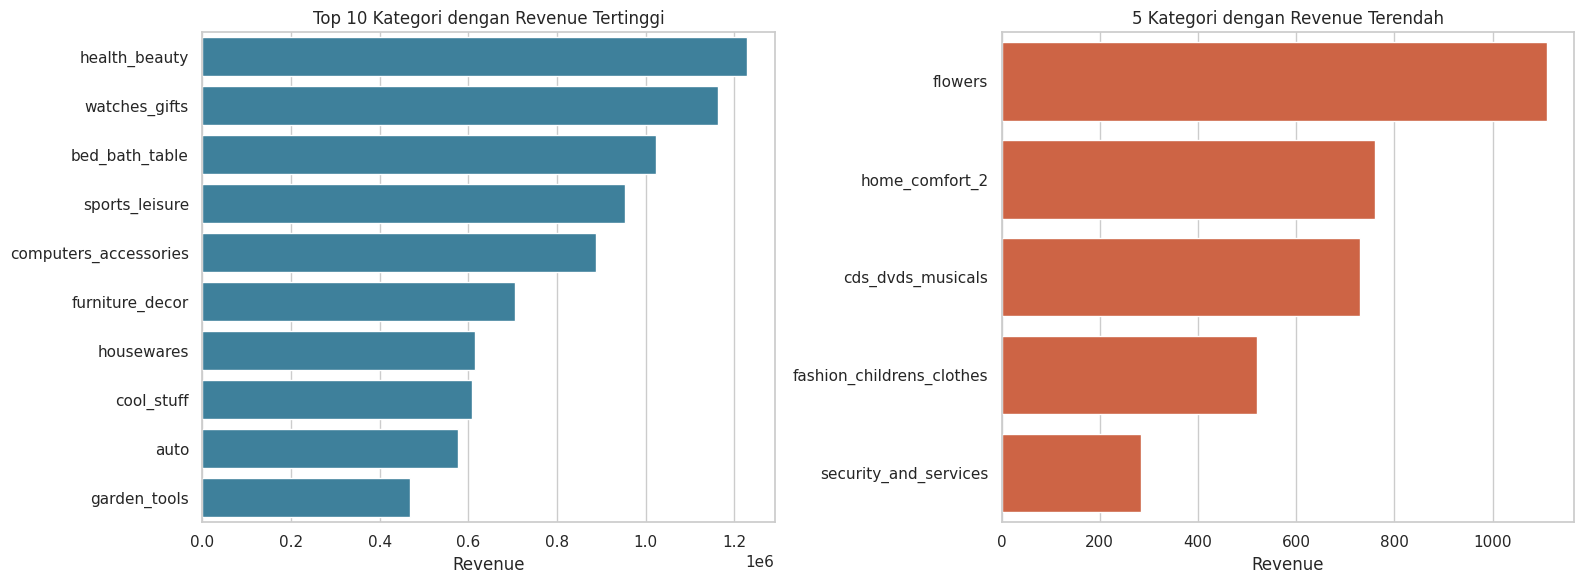

In [23]:
top10 = category_revenue.head(10)
bottom5 = category_revenue.tail(5)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=top10, x="revenue", y="category", color="#2E86AB", ax=ax[0])
ax[0].set_title("Top 10 Kategori dengan Revenue Tertinggi")
ax[0].set_xlabel("Revenue")
ax[0].set_ylabel(None)

sns.barplot(data=bottom5, x="revenue", y="category", color="#E4572E", ax=ax[1])
ax[1].set_title("5 Kategori dengan Revenue Terendah")
ax[1].set_xlabel("Revenue")
ax[1].set_ylabel(None)

plt.tight_layout()
plt.show()

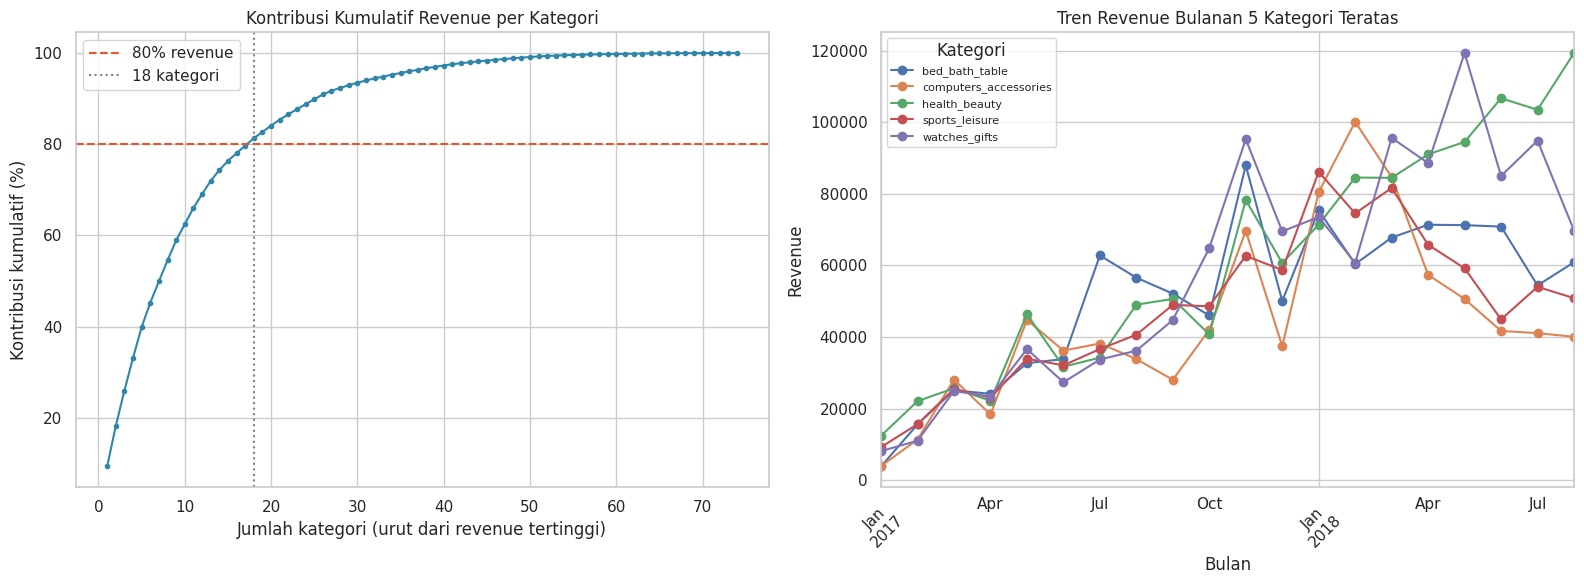

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Kontribusi kumulatif (Pareto)
ax[0].plot(range(1, len(category_revenue) + 1), category_revenue["cumulative_pct"],
           color="#2E86AB", marker="o", markersize=3)
ax[0].axhline(80, color="#E4572E", linestyle="--", label="80% revenue")
ax[0].axvline(n_80, color="gray", linestyle=":", label=f"{n_80} kategori")
ax[0].set_title("Kontribusi Kumulatif Revenue per Kategori")
ax[0].set_xlabel("Jumlah kategori (urut dari revenue tertinggi)")
ax[0].set_ylabel("Kontribusi kumulatif (%)")
ax[0].legend()

# Tren bulanan 5 kategori teratas
monthly_top5.plot(ax=ax[1], marker="o")
ax[1].set_title("Tren Revenue Bulanan 5 Kategori Teratas")
ax[1].set_xlabel("Bulan")
ax[1].set_ylabel("Revenue")
ax[1].legend(title="Kategori", fontsize=8)
ax[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

**Insight:**
- Kelima kategori teratas masing-masing menghasilkan di atas R$ 880 ribu, sedangkan kategori ke-10 (`garden_tools`) sekitar R$ 469 ribu. Lima kategori terendah hanya menghasilkan R$ 283 – R$ 1.110 per kategori.
- Kurva kumulatif menunjukkan pola ekor panjang: 18 kategori sudah mencapai 81,29% revenue, sedangkan 56 kategori sisanya hanya berbagi 18,71%.
- Pada tren bulanan 5 kategori teratas, `health_beauty` terus naik dari R$ 12.366 (Januari 2017) menjadi R$ 119.391 (Agustus 2018), tertinggi di antara lima kategori tersebut pada Agustus 2018. `watches_gifts` berfluktuasi dengan puncak sekitar R$ 119 ribu pada Mei 2018. Sebaliknya, `computers_accessories` turun dari R$ 100.132 (Februari 2018) menjadi R$ 40.053 (Agustus 2018), dan `sports_leisure` serta `bed_bath_table` cenderung melemah pada pertengahan 2018.

### Pertanyaan 2: Pengaruh keterlambatan pengiriman terhadap review score

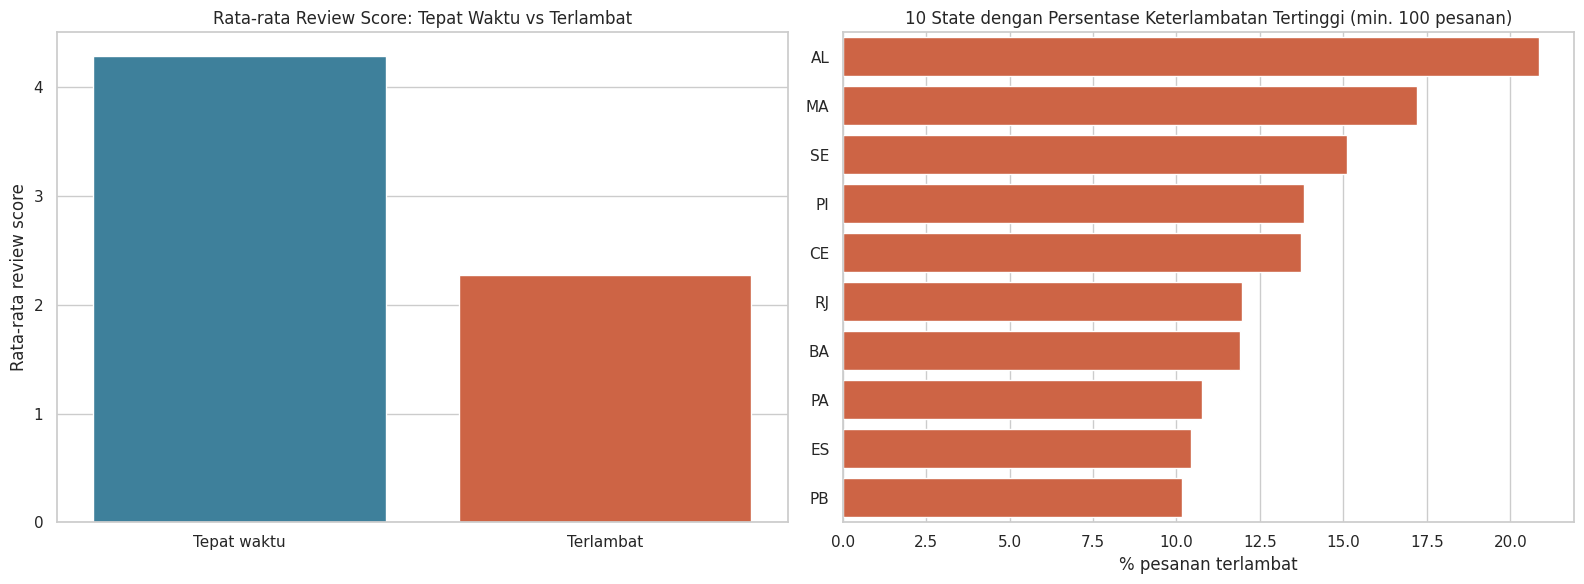

In [25]:
min_orders = 100   # state dengan pesanan sedikit membuat persentase kurang stabil
state_late_filtered = state_late[state_late["total_orders"] >= min_orders].sort_values("late_rate", ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

plot_late = review_by_late.reset_index()
plot_late["status"] = plot_late["is_late"].map({False: "Tepat waktu", True: "Terlambat"})
sns.barplot(data=plot_late, x="status", y="mean", hue="status", palette=["#2E86AB", "#E4572E"], legend=False, ax=ax[0])
ax[0].set_title("Rata-rata Review Score: Tepat Waktu vs Terlambat")
ax[0].set_xlabel(None)
ax[0].set_ylabel("Rata-rata review score")

top_state = state_late_filtered.head(10)
sns.barplot(data=top_state, x="late_rate", y="customer_state", color="#E4572E", ax=ax[1])
ax[1].set_title(f"10 State dengan Persentase Keterlambatan Tertinggi (min. {min_orders} pesanan)")
ax[1].set_xlabel("% pesanan terlambat")
ax[1].set_ylabel(None)

plt.tight_layout()
plt.show()

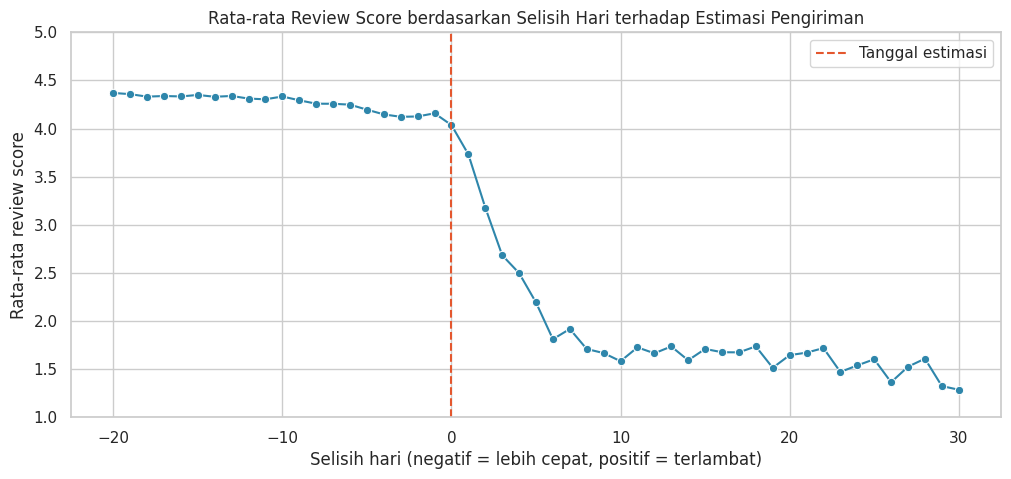

In [26]:
review_by_delay_day = (
    delivery_df[delivery_df["delay_days"].between(-20, 30)]
    .groupby("delay_days")["review_score"].mean().reset_index()
)

fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=review_by_delay_day, x="delay_days", y="review_score", marker="o", color="#2E86AB", ax=ax)
ax.axvline(0, color="#E4572E", linestyle="--", label="Tanggal estimasi")
ax.set_title("Rata-rata Review Score berdasarkan Selisih Hari terhadap Estimasi Pengiriman")
ax.set_xlabel("Selisih hari (negatif = lebih cepat, positif = terlambat)")
ax.set_ylabel("Rata-rata review score")
ax.set_ylim(1, 5)
ax.legend()
plt.show()

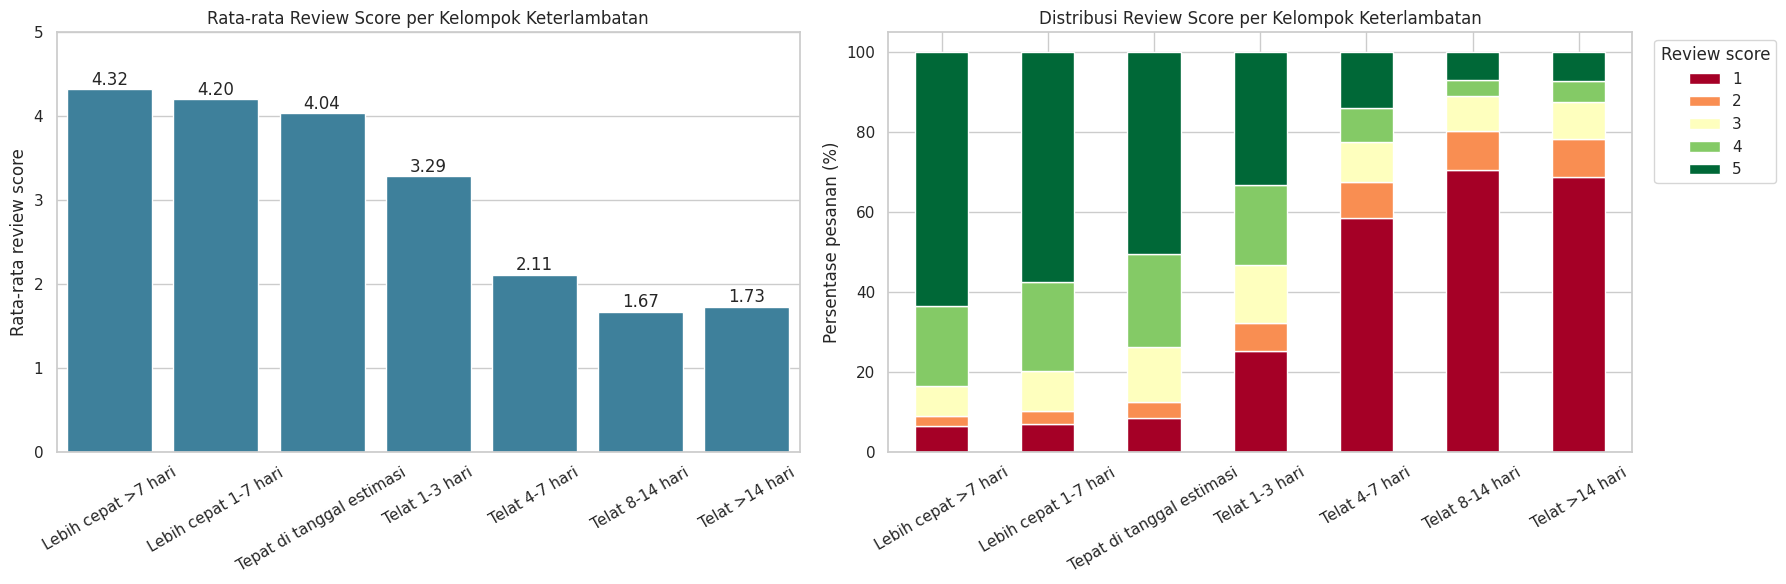

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(18, 6))

sns.barplot(data=delay_summary.reset_index(), x="delay_group", y="avg_review", color="#2E86AB", ax=ax[0])
ax[0].set_title("Rata-rata Review Score per Kelompok Keterlambatan")
ax[0].set_xlabel(None)
ax[0].set_ylabel("Rata-rata review score")
ax[0].set_ylim(0, 5)
ax[0].tick_params(axis="x", rotation=30)
for i, v in enumerate(delay_summary["avg_review"]):
    ax[0].text(i, v + 0.05, f"{v:.2f}", ha="center")

dist = pd.crosstab(delivery_df["delay_group"], delivery_df["review_rounded"], normalize="index") * 100
dist.plot(kind="bar", stacked=True, colormap="RdYlGn", ax=ax[1])
ax[1].set_title("Distribusi Review Score per Kelompok Keterlambatan")
ax[1].set_xlabel(None)
ax[1].set_ylabel("Persentase pesanan (%)")
ax[1].tick_params(axis="x", rotation=30)
ax[1].legend(title="Review score", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

**Insight:**
- Rata-rata review pesanan terlambat (2,27) kurang dari separuh pesanan tepat waktu (4,29). Dengan minimal 100 pesanan per state, 10 state dengan persentase keterlambatan tertinggi adalah AL (20,87%), MA (17,21%), SE (15,11%), PI (13,83%), CE (13,73%), RJ (11,96%), BA (11,90%), PA (10,76%), ES (10,43%), dan PB (10,18%). Tujuh dari sepuluh state tersebut berada di wilayah Timur Laut Brasil. State dengan pesanan sangat sedikit (misalnya RR, 40 pesanan) tidak diikutkan karena persentasenya tidak stabil.
- RJ memiliki persentase keterlambatan lebih rendah dibanding state teratas, tetapi dengan 12.172 pesanan jumlah pesanan terlambatnya mencapai 1.456, sehingga dampak absolutnya besar.
- Grafik garis menunjukkan titik patah tepat di tanggal estimasi: review stabil di kisaran 4,2–4,4 saat pesanan sampai lebih cepat dan 4,04 pada hari estimasi, lalu anjlok menjadi 3,73 (telat 1 hari), 3,18 (2 hari), 2,68 (3 hari), 2,19 (5 hari), dan 1,92 (7 hari). Setelah sekitar 10 hari terlambat, rata-rata review relatif mendatar di kisaran 1,5–1,7 hingga sekitar hari ke-25.
- Pada grafik per kelompok, sampai lebih cepat dari estimasi hanya memberi selisih kecil (4,04–4,32), sedangkan keterlambatan langsung menggeser distribusi review ke bintang 1: porsi bintang 1 sekitar 25% pada telat 1–3 hari dan di atas 58% pada telat lebih dari 3 hari.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Revenue periode Januari 2017 – Agustus 2018 (R$ 13,18 juta) sangat terkonsentrasi pada segelintir kategori. Sepuluh kategori dengan revenue tertinggi menyumbang R$ 8.232.900,46 atau 62,47% dari total revenue, dan lima kategori teratas saja menyumbang 39,88%. Secara kumulatif, 18 dari 74 kategori sudah mencakup 81,29% revenue. Berikut 10 kategori dengan revenue tertinggi:

| Peringkat | Kategori | Revenue (R$) | Kontribusi terhadap total revenue |
|---|---|---|---|
| 1 | `health_beauty` | 1.229.557,50 | 9,33% |
| 2 | `watches_gifts` | 1.163.187,91 | 8,83% |
| 3 | `bed_bath_table` | 1.022.955,77 | 7,76% |
| 4 | `sports_leisure` | 952.661,40 | 7,23% |
| 5 | `computers_accessories` | 887.944,60 | 6,74% |
| 6 | `furniture_decor` | 706.237,17 | 5,36% |
| 7 | `housewares` | 614.341,62 | 4,66% |
| 8 | `cool_stuff` | 609.158,00 | 4,62% |
| 9 | `auto` | 577.721,09 | 4,38% |
| 10 | `garden_tools` | 469.135,40 | 3,56% |

Sebaliknya, lima kategori dengan revenue terendah hanya menyumbang 0,03% dari total revenue:

| Kategori | Revenue (R$) | Kontribusi terhadap total revenue |
|---|---|---|
| `flowers` | 1.110,04 | 0,0084% |
| `home_comfort_2` | 760,27 | 0,0058% |
| `cds_dvds_musicals` | 730,00 | 0,0055% |
| `fashion_childrens_clothes` | 519,95 | 0,0039% |
| `security_and_services` | 283,29 | 0,0021% |

Revenue kategori lebih ditentukan oleh volume penjualan (korelasi 0,95 dengan jumlah item terjual) daripada harga. Dari sisi tren, `health_beauty` terus naik, sedangkan `computers_accessories` turun dari R$ 100 ribu (Februari 2018) menjadi R$ 40 ribu (Agustus 2018).

- **Conclusion pertanyaan 2:** Keterlambatan pengiriman berpengaruh besar terhadap kepuasan pelanggan. Pesanan terlambat (6,67% dari seluruh pesanan) rata-rata mendapat review 2,27 dibanding 4,29 untuk pesanan tepat waktu (turun 2,02 poin atau 47,1%), dan proporsi review rendah naik dari 9,2% menjadi 62,4%. Pengaruhnya muncul tepat setelah lewat tanggal estimasi: rata-rata review turun menjadi 3,29 (telat 1–3 hari), 2,11 (telat 4–7 hari), dan sekitar 1,7 (telat lebih dari 7 hari), sedangkan sampai lebih cepat dari estimasi hanya memberi selisih kecil. Berikut 10 state dengan persentase pesanan terlambat tertinggi (minimal 100 pesanan):

| Peringkat | State | Total pesanan | Pesanan terlambat | Persentase terlambat |
|---|---|---|---|---|
| 1 | AL (Alagoas) | 393 | 82 | 20,87% |
| 2 | MA (Maranhão) | 709 | 122 | 17,21% |
| 3 | SE (Sergipe) | 331 | 50 | 15,11% |
| 4 | PI (Piauí) | 470 | 65 | 13,83% |
| 5 | CE (Ceará) | 1.267 | 174 | 13,73% |
| 6 | RJ (Rio de Janeiro) | 12.172 | 1.456 | 11,96% |
| 7 | BA (Bahia) | 3.226 | 384 | 11,90% |
| 8 | PA (Pará) | 929 | 100 | 10,76% |
| 9 | ES (Espírito Santo) | 1.966 | 205 | 10,43% |
| 10 | PB (Paraíba) | 511 | 52 | 10,18% |

Tujuh dari sepuluh state tersebut (AL, MA, SE, PI, CE, BA, PB) berada di wilayah Timur Laut Brasil. Secara total terdapat 2.690 pesanan terlambat dari 21.974 pesanan di sepuluh state ini (12,24%). RJ memiliki persentase yang lebih rendah dibanding state teratas, tetapi jumlah pesanan terlambatnya paling banyak (1.456).

**Rekomendasi Action Item:**
- **Fokuskan stok dan promosi pada kategori inti.** Prioritaskan ketersediaan stok dan kampanye untuk 18 kategori yang menyumbang lebih dari 80% revenue, terutama `health_beauty` dan `watches_gifts` yang tren-nya naik. Selidiki penyebab turunnya `computers_accessories` sejak Februari 2018 (harga, stok, atau persaingan), serta evaluasi kategori dengan revenue sangat kecil (misalnya `security_and_services` dan `fashion_childrens_clothes`) untuk dikurangi atau diuji dengan promosi sebelum dihentikan.
- **Tekan keterlambatan, terutama di wilayah Timur Laut.** Evaluasi ekspedisi dan atur estimasi pengiriman yang lebih realistis di AL, MA, SE, PI, dan CE. Tetapkan target maksimum keterlambatan 3 hari, karena review turun tajam setelah itu (2,11 pada telat 4–7 hari), dan pantau persentase keterlambatan per state setiap minggu.
- **Tangani pesanan yang berisiko terlambat secara proaktif.** Kirim notifikasi dan tawarkan kompensasi (misalnya voucher) ketika pesanan diperkirakan melewati tanggal estimasi, untuk mencegah review bintang 1 yang mencapai lebih dari 58% pada keterlambatan di atas 3 hari.